In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("E-commerce project started")


E-commerce project started


In [ ]:
df = pd.read_csv('/content/ecommerce_sales.csv')
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Segment,Product,Category,Quantity,Unit_Price,Discount_Percent,Sales,Cost,Profit,Region,Payment_Method,Order_Status
0,ORD1001,2025-07-12,CUST1147,Returning,Bedsheet,Home & Kitchen,2,1132,0,0.0,1232.72,0.00,West,Cash on Delivery,Cancelled
1,ORD1002,2025-05-27,CUST1124,Returning,Speaker,Electronics,2,1943,0,0.0,2671.26,0.00,East,Credit Card,Returned
2,ORD1003,2025-09-13,CUST1054,Loyal,Handbag,Fashion,1,2020,5,0.0,1448.55,0.00,East,Net Banking,Cancelled
3,ORD1004,2025-09-29,CUST1103,Returning,Storage Box,Home & Kitchen,1,701,10,630.9,392.64,238.26,South,Net Banking,Delivered
4,ORD1005,2025-09-08,CUST1072,New,Handbag,Fashion,2,1807,15,3071.9,2001.36,1070.54,East,Cash on Delivery,Delivered


In [ ]:
df.shape

(500, 15)

In [ ]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Segment', 'Product',
       'Category', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Sales',
       'Cost', 'Profit', 'Region', 'Payment_Method', 'Order_Status'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          500 non-null    object 
 1   Order_Date        500 non-null    object 
 2   Customer_ID       500 non-null    object 
 3   Customer_Segment  500 non-null    object 
 4   Product           500 non-null    object 
 5   Category          500 non-null    object 
 6   Quantity          500 non-null    int64  
 7   Unit_Price        500 non-null    int64  
 8   Discount_Percent  500 non-null    int64  
 9   Sales             500 non-null    float64
 10  Cost              500 non-null    float64
 11  Profit            500 non-null    float64
 12  Region            500 non-null    object 
 13  Payment_Method    500 non-null    object 
 14  Order_Status      500 non-null    object 
dtypes: float64(3), int64(3), object(9)
memory usage: 58.7+ KB


In [ ]:
df.describe()

,Quantity,Unit_Price,Discount_Percent,Sales,Cost,Profit
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2.500000,1357.716000,9.330000,1766.646300,2167.216660,508.205380
std,1.120943,945.696642,7.169652,2463.228841,1959.013351,783.311309
min,1.000000,213.000000,0.000000,0.000000,128.810000,0.000000
25%,1.750000,470.000000,5.000000,0.000000,778.277500,0.000000
50%,2.000000,1210.500000,10.000000,819.600000,1437.155000,189.920000
75%,4.000000,1947.000000,15.000000,2571.275000,2911.047500,661.867500
max,4.000000,3827.000000,20.000000,13246.800000,11578.490000,5141.460000


MISSING VALUES CHECK

In [ ]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Segment,0
Product,0
Category,0
Quantity,0
Unit_Price,0
Discount_Percent,0
Sales,0


Duplicate values check

In [ ]:
df.duplicated().sum()

np.int64(0)

Duplicate value remove

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

In [ ]:
df.dtypes

,0
Order_ID,object
Order_Date,datetime64[ns]
Customer_ID,object
Customer_Segment,object
Product,object
Category,object
Quantity,int64
Unit_Price,int64
Discount_Percent,int64
Sales,float64


In [ ]:
df['month']= df['Order_Date'].dt.month_name()

In [ ]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Segment,Product,Category,Quantity,Unit_Price,Discount_Percent,Sales,Cost,Profit,Region,Payment_Method,Order_Status,month
0,ORD1001,2025-07-12,CUST1147,Returning,Bedsheet,Home & Kitchen,2,1132,0,0.0,1232.72,0.00,West,Cash on Delivery,Cancelled,July
1,ORD1002,2025-05-27,CUST1124,Returning,Speaker,Electronics,2,1943,0,0.0,2671.26,0.00,East,Credit Card,Returned,May
2,ORD1003,2025-09-13,CUST1054,Loyal,Handbag,Fashion,1,2020,5,0.0,1448.55,0.00,East,Net Banking,Cancelled,September
3,ORD1004,2025-09-29,CUST1103,Returning,Storage Box,Home & Kitchen,1,701,10,630.9,392.64,238.26,South,Net Banking,Delivered,September
4,ORD1005,2025-09-08,CUST1072,New,Handbag,Fashion,2,1807,15,3071.9,2001.36,1070.54,East,Cash on Delivery,Delivered,September


In [ ]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order_ID'].nunique()
total_customers = df['Customer_ID'].nunique()
total_quantity = df['Quantity'].sum()

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)

Total Sales: 883323.15
Total Profit: 254102.69
Total Orders: 500
Total Customers: 147
Total Quantity Sold: 1250


In [ ]:
category_sales = df.groupby('Category')['Sales'].sum()

print(category_sales)

Category
Beauty             40381.55
Electronics       348883.75
Fashion           286892.90
Home & Kitchen    207164.95
Name: Sales, dtype: float64


Category-wise sales bar chart

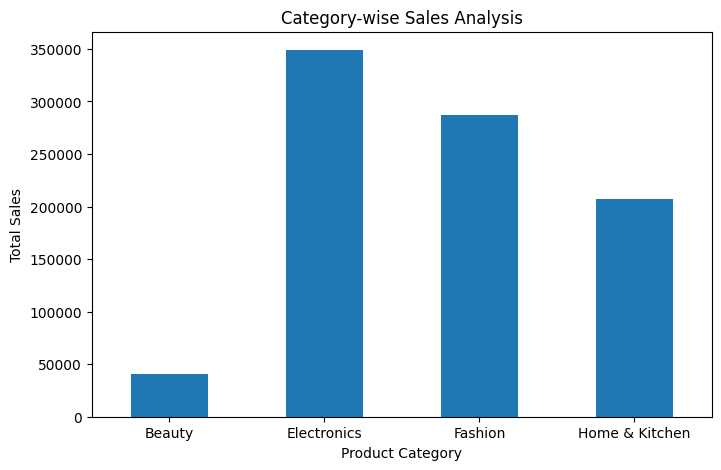

In [ ]:
category_sales.plot(kind='bar', figsize=(8,5))

plt.title('Category-wise Sales Analysis')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

month wise sales

In [ ]:
monthly_sales = df.groupby('month')['Sales'].sum()

print(monthly_sales)

month
April         73852.80
August        73427.55
December      61581.35
February      79331.95
January       88509.25
July          89022.90
June          52396.55
March         79175.50
May           86288.15
November      51474.30
October       47171.60
September    101091.25
Name: Sales, dtype: float64


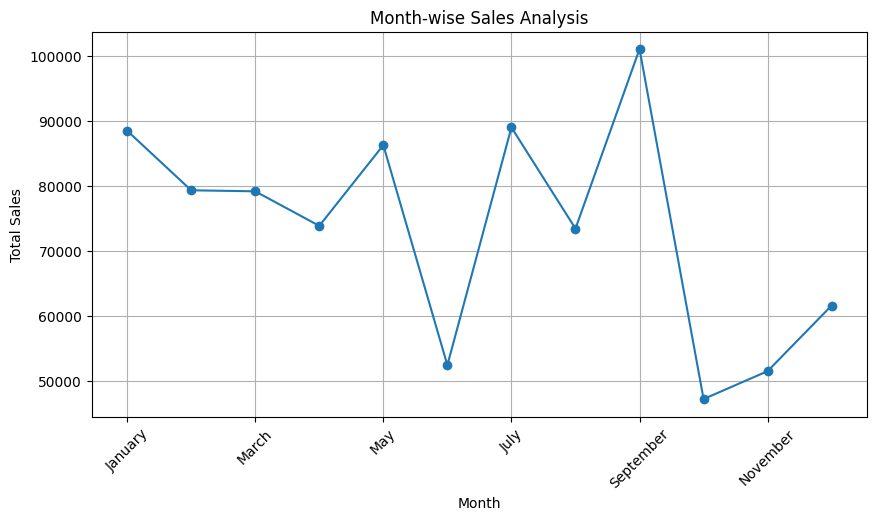

In [ ]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

monthly_sales.plot(kind='line', marker='o', figsize=(10,5))

plt.title('Month-wise Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

The Month-wise Sales Graph helps us understand the monthly sales performance of an e-commerce business. It helps identify sales trends and shows whether sales are increasing or decreasing over time.

Create a Bar Chart to visualize total sales for each product.

In [ ]:
Product_sales = df.groupby('Product')['Sales'].sum()
print(Product_sales)

Product
Bedsheet           59043.25
Bottle             22925.85
Face Wash           4306.70
Handbag            63757.25
Headphones        106788.25
Jeans              60934.45
Mixer Grinder      99750.35
Moisturizer        12714.95
Shampoo             6738.90
Smart Watch       125265.85
Sneakers          136950.35
Speaker            97000.00
Storage Box        25445.50
Sunscreen          16621.00
T-Shirt            25250.85
Wireless Mouse     19829.65
Name: Sales, dtype: float64


In [ ]:
create a bar chart to visualize total sales for each product

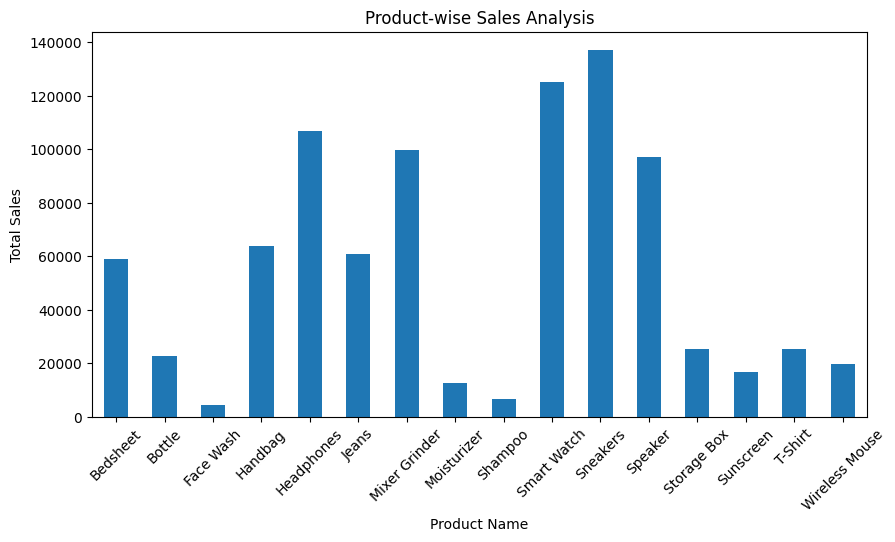

In [ ]:
Product_sales.plot(kind='bar', figsize=(10,5))

plt.title('Product-wise Sales Analysis')
plt.xlabel('Product Name')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

To compare the sales of different products and identify the best-selling and lowest-selling products.

Claculate total sales for each region

In [ ]:
region_sales = df.groupby('Region')['Sales'].sum()
print(region_sales)

Region
Central    153321.45
East       168723.50
North      203694.85
South      169298.25
West       188285.10
Name: Sales, dtype: float64


to compare sales across different region and identify the best programs

create the bar chart to visulize total sales in each region

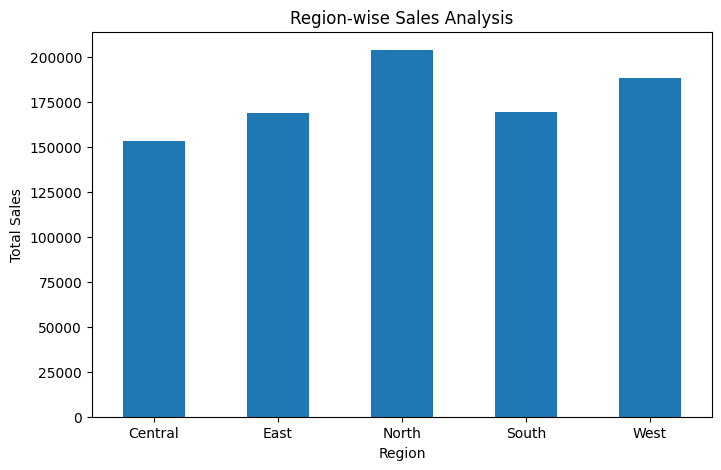

In [ ]:
region_sales.plot(kind='bar', figsize=(8,5))

plt.title('Region-wise Sales Analysis')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

calculate the total sales for each payment mothod

In [ ]:
Payment_sales= df.groupby('Payment_Method')['Sales'].sum()
print(Payment_sales)

Payment_Method
Cash on Delivery    161398.95
Credit Card         136422.40
Debit Card          216984.00
Net Banking         157754.40
UPI                 210763.40
Name: Sales, dtype: float64


Create a Pie Chart to visualize sales distribution by payment method.

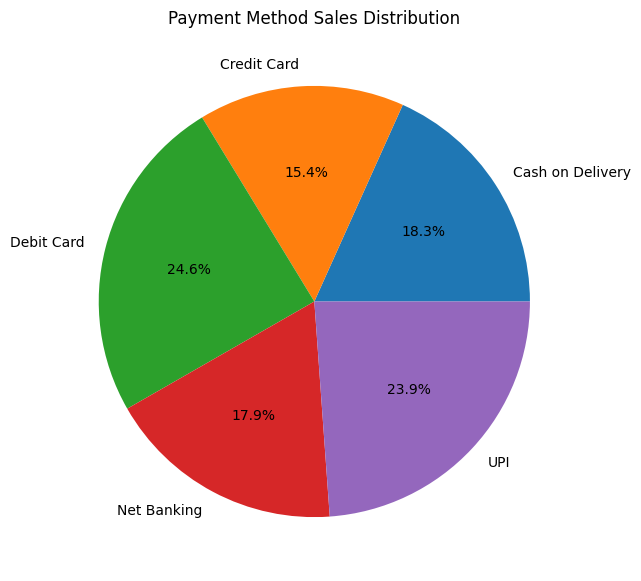

In [ ]:
Payment_sales.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7,7)
)

plt.title('Payment Method Sales Distribution')
plt.ylabel(' ')
plt.show()

Create a Bar Chart to display the sales generated by the top 10 customers.

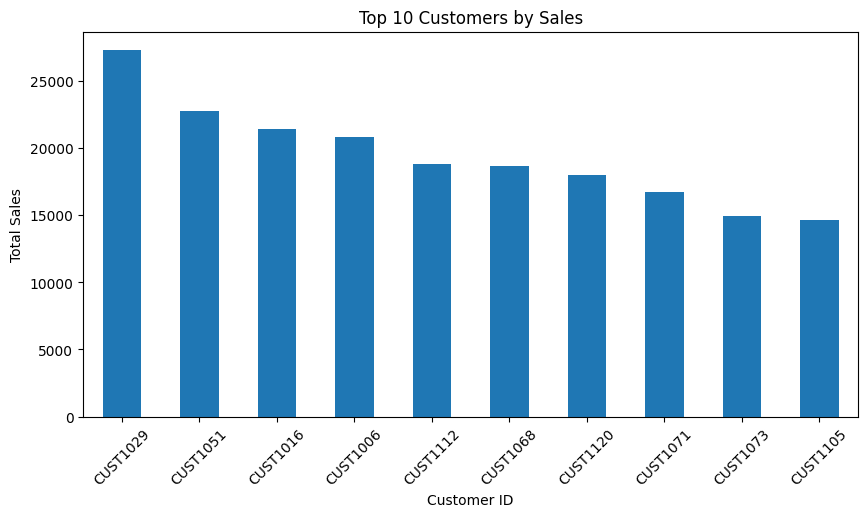

In [ ]:
customer_sales = df.groupby('Customer_ID')['Sales'].sum()

top_customers = customer_sales.sort_values(ascending=False).head(10)

top_customers.plot(kind='bar', figsize=(10,5))

plt.title('Top 10 Customers by Sales')
plt.xlabel('Customer ID')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

Calculate the total profit generated by each product category.

In [ ]:
category_profit = df.groupby('Category')['Profit'].sum()

print(category_profit)

Category
Beauty             12182.97
Electronics       102561.20
Fashion            76817.86
Home & Kitchen     62540.66
Name: Profit, dtype: float64
